# Ensemble: HistGradientBoosting + Random Forest + Regressor ordinal

## Previsões *out-of-fold* (OOF)

Com validação cruzada de 5 folds, cada pessoa do treino fica de fora **exatamente uma vez**. A previsão
*out-of-fold* de uma pessoa é a que o modelo desse fold fez para ela — um modelo que **nunca a viu** no treino.
Juntando os 5 folds, ficamos com uma previsão "honesta" para **todas** as 10 962 pessoas.

Porque é preciso: o ensemble também é um modelo que aprende (aprende a combinar os três). Se aprendesse com
previsões de modelos que já viram as respostas, veria um HGB e um RF quase perfeitos (F1 de treino ≈ 1) e
aprenderia a confiar cegamente neles — o que no teste não se confirma. Com OOF, vê os modelos tal como eles se
portam em pessoas novas.

Os três modelos usaram **os mesmos 5 folds** (`StratifiedKFold`, `random_state=42`). Por isso, quando o ensemble
é validado no fold *k*, nenhum dos três modelos viu essas pessoas.

## Formas de combinar (todas avaliadas da mesma forma)

| Forma | Como funciona |
|---|---|
| Modelos sozinhos | referência |
| **Média ponderada** (soft voting) HGB + RF | `w × prob HGB + (1−w) × prob RF`; o peso `w` é escolhido em 4 folds e testado no 5.º |
| **Stacking** HGB + RF | regressão logística que recebe as 32 probabilidades e aprende a combiná-las |
| **Stacking** HGB + RF + regressor | o mesmo + a previsão contínua do regressor (o regressor não dá probabilidades, só entra assim) |
| Stacking + pesos por classe | ajuste final da decisão para o Macro F1, como no RF |

**Avaliação sem leakage:** o que o ensemble aprende (o peso `w`, a regressão logística, os pesos por classe) é
sempre aprendido nas OOF de 4 folds e medido no 5.º — os mesmos 5 folds.

O stacking é, em teoria, o mais forte: em vez de um peso fixo, aprende **quando** confiar em cada modelo
(ex: em que faixas o regressor ajuda). Mas pode não ganhar — é isso que este notebook mede.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, classification_report
from IPython.display import display

P = [f"p_{k}" for k in range(16)]
oof_hgb = pd.read_csv("../resultados/oof_hgb.csv")
oof_rf = pd.read_csv("../resultados/oof_rf.csv")
oof_reg = pd.read_csv("../resultados/oof_regressor.csv")
test_hgb = pd.read_csv("../resultados/test_proba_hgb.csv")
test_rf = pd.read_csv("../resultados/test_proba_rf.csv")
test_reg = pd.read_csv("../resultados/test_regressor.csv")

# As linhas têm de ser as mesmas pessoas, pela mesma ordem, nos três ficheiros
assert (oof_hgb["PID"] == oof_rf["PID"]).all() and (oof_hgb["PID"] == oof_reg["PID"]).all()
assert (oof_hgb["real"] == oof_rf["real"]).all() and (oof_hgb["real"] == oof_reg["real"]).all()
assert len(test_hgb) == len(test_rf) == len(test_reg) == 3655

y = oof_hgb["real"].values
proba = {"HGB": oof_hgb[P].values, "RF": oof_rf[P].values}
proba_teste = {"HGB": test_hgb[P].values, "RF": test_rf[P].values}
reg, reg_teste = oof_reg["reg_continua"].values, test_reg["reg_continua"].values

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(cv.split(np.zeros(len(y)), y))       # os folds só dependem de y e do nº de linhas: são os mesmos
print("Pessoas:", len(y))

Pessoas: 10962


## Funções

- `avaliar(nome, aprender, prever)`: para cada fold, `aprender` usa só as OOF dos outros 4 folds e `prever`
  aplica ao fold que ficou de fora. Devolve o F1 de cada fold e as previsões (do ensemble) de todas as pessoas.
- `entradas(...)`: as colunas que o stacking recebe. As probabilidades entram em **logaritmo**: a regressão
  logística soma as entradas, e somar logaritmos de probabilidades é o mesmo que multiplicá-las
  (combinar "evidência"), o que funciona melhor do que somar probabilidades. Tudo é normalizado (`StandardScaler`).
- `pesos_por_classe` e `otimizar_cortes`: as mesmas funções do RF e do regressor.

In [2]:
resultados, previsoes = {}, {}

def avaliar(nome, aprender, prever):
    pred = np.zeros(len(y), dtype=int)
    f1s = []
    for a, b in folds:
        modelo = aprender(a)
        pred[b] = prever(modelo, b)
        f1s.append(f1_score(y[b], pred[b], average="macro"))
    resultados[nome], previsoes[nome] = f1s, pred
    print(f"{nome:45s} Macro F1 {np.mean(f1s):.4f} ± {np.std(f1s):.4f}")

def entradas(idx=None, com_regressor=True, teste=False):
    fontes = proba_teste if teste else proba
    r = reg_teste if teste else reg
    blocos = [np.log(np.clip(fontes[m], 1e-6, 1)) for m in ["HGB", "RF"]]
    if com_regressor:
        blocos.append(r[:, None])
    Z = np.hstack(blocos)
    return Z if idx is None else Z[idx]

def criar_stacking():
    return make_pipeline(StandardScaler(),
                         LogisticRegression(C=1.0, class_weight="balanced", max_iter=3000))

def pesos_por_classe(p, yy, n_rounds=3, grid=np.linspace(0.5, 2.5, 21)):
    w = np.ones(p.shape[1])
    best = f1_score(yy, (p * w).argmax(1), average="macro")
    for _ in range(n_rounds):
        for k in range(len(w)):
            for g in grid:
                w2 = w.copy(); w2[k] = g
                s = f1_score(yy, (p * w2).argmax(1), average="macro")
                if s > best + 1e-6:
                    best, w = s, w2
    return w

def otimizar_cortes(previsao, y_real, passagens=3):
    cortes = np.arange(0.5, 15, 1.0)
    melhor = f1_score(y_real, np.digitize(previsao, cortes), average="macro")
    for _ in range(passagens):
        for k in range(len(cortes)):
            baixo = cortes[k - 1] if k > 0 else previsao.min()
            cima = cortes[k + 1] if k < len(cortes) - 1 else previsao.max()
            for valor in np.linspace(baixo, cima, 21)[1:-1]:
                tentativa = cortes.copy(); tentativa[k] = valor
                f = f1_score(y_real, np.digitize(previsao, tentativa), average="macro")
                if f > melhor:
                    melhor, cortes = f, tentativa
    return cortes

## 1. Modelos sozinhos

In [3]:
avaliar("HGB sozinho", lambda a: None, lambda m, b: proba["HGB"][b].argmax(1))
avaliar("RF sozinho", lambda a: None, lambda m, b: proba["RF"][b].argmax(1))
avaliar("Regressor sozinho (cortes otimizados)",
        lambda a: otimizar_cortes(reg[a], y[a]), lambda cortes, b: np.digitize(reg[b], cortes))

HGB sozinho                                   Macro F1 0.5891 ± 0.0128
RF sozinho                                    Macro F1 0.5115 ± 0.0066


Regressor sozinho (cortes otimizados)         Macro F1 0.4751 ± 0.0118


## 2. Média ponderada HGB + RF (soft voting)

O peso `w` do HGB é escolhido nos 4 folds de treino (de 0 a 1, de 0,05 em 0,05) e testado no 5.º.

In [4]:
PESOS_W = np.round(np.arange(0, 1.0001, 0.05), 2)

def melhor_w(a):
    f = [f1_score(y[a], (w * proba["HGB"][a] + (1 - w) * proba["RF"][a]).argmax(1), average="macro") for w in PESOS_W]
    return PESOS_W[int(np.argmax(f))]

avaliar("Média ponderada HGB + RF", melhor_w,
        lambda w, b: (w * proba["HGB"][b] + (1 - w) * proba["RF"][b]).argmax(1))
print("Peso do HGB escolhido com todas as OOF:", melhor_w(np.arange(len(y))))

Média ponderada HGB + RF                      Macro F1 0.5875 ± 0.0125
Peso do HGB escolhido com todas as OOF: 0.8


## 3. Stacking

In [5]:
avaliar("Stacking HGB + RF",
        lambda a: criar_stacking().fit(entradas(a, com_regressor=False), y[a]),
        lambda m, b: m.predict(entradas(b, com_regressor=False)))
avaliar("Stacking HGB + RF + regressor",
        lambda a: criar_stacking().fit(entradas(a), y[a]),
        lambda m, b: m.predict(entradas(b)))

Stacking HGB + RF                             Macro F1 0.5937 ± 0.0107


Stacking HGB + RF + regressor                 Macro F1 0.5945 ± 0.0105


### Stacking + pesos por classe

Primeiro calculam-se as probabilidades do stacking para cada fold (aprendido nos outros 4). Depois os pesos por
classe são aprendidos nessas probabilidades em 4 folds e testados no 5.º.

In [6]:
proba_stack = np.zeros((len(y), 16))
for a, b in folds:
    proba_stack[b] = criar_stacking().fit(entradas(a), y[a]).predict_proba(entradas(b))

avaliar("Stacking HGB + RF + regressor + pesos por classe",
        lambda a: pesos_por_classe(proba_stack[a], y[a]), lambda w, b: (proba_stack[b] * w).argmax(1))

Stacking HGB + RF + regressor + pesos por classe Macro F1 0.5918 ± 0.0123


## 4. Comparação

Como os folds são os mesmos, comparamos também **fold a fold** com o HGB sozinho (o melhor modelo individual):
uma forma que ganha nos 5 folds tem uma vantagem sólida; 3 em 5 pode ser sorte.

In [7]:
tabela = pd.DataFrame({
    "Macro F1": {n: np.mean(f) for n, f in resultados.items()},
    "desvio": {n: np.std(f) for n, f in resultados.items()},
    "ganho vs HGB": {n: np.mean(f) - np.mean(resultados["HGB sozinho"]) for n, f in resultados.items()},
    "folds em que bate o HGB": {n: int((np.array(f) > np.array(resultados["HGB sozinho"])).sum())
                                for n, f in resultados.items()},
}).sort_values("Macro F1", ascending=False)
display(tabela.round(4))
display(pd.DataFrame(resultados, index=[f"fold {k}" for k in range(1, 6)]).round(4))

,Macro F1,desvio,ganho vs HGB,folds em que bate o HGB
Stacking HGB + RF + regressor,0.5945,0.0105,0.0055,3
Stacking HGB + RF,0.5937,0.0107,0.0046,2
Stacking HGB + RF + regressor + pesos por classe,0.5918,0.0123,0.0027,2
HGB sozinho,0.5891,0.0128,0.0000,0
Média ponderada HGB + RF,0.5875,0.0125,-0.0016,2
RF sozinho,0.5115,0.0066,-0.0776,0
Regressor sozinho (cortes otimizados),0.4751,0.0118,-0.1140,0


,HGB sozinho,RF sozinho,Regressor sozinho (cortes otimizados),Média ponderada HGB + RF,Stacking HGB + RF,Stacking HGB + RF + regressor,Stacking HGB + RF + regressor + pesos por classe
fold 1,0.6031,0.5062,0.4780,0.5983,0.5981,0.5997,0.5966
fold 2,0.5713,0.5183,0.4775,0.5722,0.6020,0.6024,0.6030
fold 3,0.6024,0.5145,0.4528,0.6035,0.6056,0.6065,0.6049
fold 4,0.5907,0.5169,0.4794,0.5892,0.5858,0.5837,0.5784
fold 5,0.5779,0.5013,0.4879,0.5743,0.5770,0.5803,0.5759


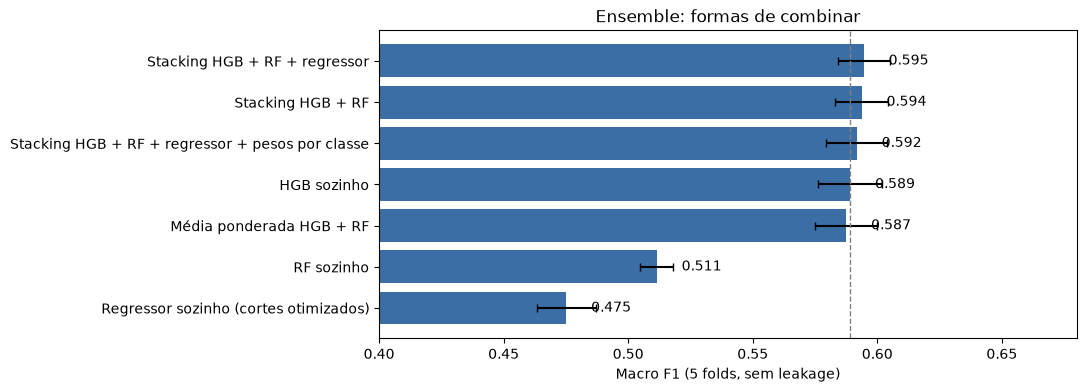

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
t = tabela.sort_values("Macro F1")
ax.barh(t.index, t["Macro F1"], xerr=t["desvio"], color="#3b6ea5", capsize=3)
for i, v in enumerate(t["Macro F1"]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")
ax.axvline(tabela.loc["HGB sozinho", "Macro F1"], color="grey", ls="--", lw=1)
ax.set_xlim(0.4, 0.68)
ax.set_xlabel("Macro F1 (5 folds, sem leakage)")
ax.set_title("Ensemble: formas de combinar")
plt.show()

### Onde muda: F1 por faixa

Comparação do HGB sozinho com o melhor ensemble — em que faixas ganha (ou perde).

In [9]:
melhor = tabela.index[0]
por_faixa = pd.DataFrame({"HGB sozinho": f1_score(y, previsoes["HGB sozinho"], average=None),
                          melhor: f1_score(y, previsoes[melhor], average=None),
                          "pessoas": np.bincount(y)})
por_faixa["diferença"] = por_faixa[melhor] - por_faixa["HGB sozinho"]
por_faixa.round(3)

,HGB sozinho,Stacking HGB + RF + regressor,pessoas,diferença
0,0.850,0.846,207,-0.004
1,0.321,0.460,172,0.140
2,0.595,0.537,399,-0.058
3,0.397,0.423,377,0.027
4,0.306,0.303,449,-0.003
5,0.386,0.394,647,0.008
6,0.361,0.377,859,0.016
7,0.430,0.419,862,-0.011
8,0.653,0.664,905,0.012
9,0.788,0.793,1014,0.005


## 5. Submissão com a melhor forma

O que o ensemble aprende é agora aprendido com **todas** as OOF e aplicado às previsões do teste
(que vêm dos modelos treinados com todos os dados de treino).

In [10]:
print("Melhor forma:", melhor)
todos = np.arange(len(y))

if melhor == "HGB sozinho":
    previsao_teste = proba_teste["HGB"].argmax(1)
elif melhor == "RF sozinho":
    previsao_teste = proba_teste["RF"].argmax(1)
elif melhor.startswith("Regressor"):
    previsao_teste = np.digitize(reg_teste, otimizar_cortes(reg, y))
elif melhor.startswith("Média ponderada"):
    w = melhor_w(todos)
    previsao_teste = (w * proba_teste["HGB"] + (1 - w) * proba_teste["RF"]).argmax(1)
else:
    com_reg = "regressor" in melhor
    stack = criar_stacking().fit(entradas(com_regressor=com_reg), y)
    p = stack.predict_proba(entradas(com_regressor=com_reg, teste=True))
    if "pesos por classe" in melhor:
        p = p * pesos_por_classe(proba_stack, y)
    previsao_teste = p.argmax(1)

sub = pd.read_csv("../dados/example_submission_10.csv")
sub["AGE_RANGE"] = previsao_teste.astype(int)
assert len(sub) == 3655 and sub["RowId"].tolist() == list(range(3655))
sub.to_csv("../submissions/ensemble_submission.csv", index=False)
print("Gravado: ../submissions/ensemble_submission.csv")
print(sub["AGE_RANGE"].value_counts().sort_index().to_dict())

Melhor forma: Stacking HGB + RF + regressor


Gravado: ../submissions/ensemble_submission.csv
{0: 69, 1: 70, 2: 119, 3: 200, 4: 144, 5: 186, 6: 240, 7: 295, 8: 303, 9: 376, 10: 321, 11: 358, 12: 288, 13: 269, 14: 203, 15: 214}


## Conclusão

- _(escreve aqui que forma ganhou, por quanto, e em que faixas o ensemble ajuda)_